##### CSC 1105 Mathematics for Computer Science
# Data Analysis with Python
## Matrix Algebra, Vectors and Vector Spaces

**Group Assignment**

- **Maximum group size:** 6 members
- **Deadline:** October 26, 2026, at 11:59 PM EAT
- **Purpose:** Investigate synthetic mobile money transactions using pandas, NumPy, and plots.

## Group Members

| No. | Name | Registration Number |
|:---:|---|---|
| 1 | ABIRO FAITH FAUSTINE | 26/U/03467/PSA |
| 2 | SSEMBUYA PUIS | 26/U/04171/PS |
| 3 | TUYISHIME JEANPIRRE | 26/E/26540/PSA |
| 4 | SSEMAGANDA TRAVIS BENJAMIN | 26/U/03637/PSA |
| 5 | NDAWULA PRAISE MARGARET | 26/U/03619/PSA |
| 6 | MAJALIWA WILFRED | 26/E/32173/PSA |

#

## Question 1: Load, Audit, and Explore the Data

### 1(a) Describe the Simulation and Fraud Label

**Explain how the mobile money transaction data was simulated and what the `isFraud` label represents**

MoMTSim is a tool that creates fake mobile money transactions that behave statistically like real transactions. It simulates normal activities, such as sending and withdrawing money, as well as fraudulent activities, such as account takeover and fraud using fake credentials.

The `isFraud` column tells us whether a transaction is fraudulent: 1 means fraudulent, while 0 means legitimate. It is the outcome we want our model to predict, not information the model should use to make its prediction.

### 1(b) Data Quality Audit

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "MoMTSim_20240722202413_1000_dataset.csv",
    dtype={"initiator": "string", "recipient": "string"}
)

# 1. Dataset dimensions
print("===== DATASET DIMENSIONS =====")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# 2. Data types
print("\n===== DATA TYPES =====")
print(df.dtypes)

===== DATASET DIMENSIONS =====
Rows: 4225958
Columns: 10

===== DATA TYPES =====
step                 int64
transactionType        str
amount             float64
initiator           string
oldBalInitiator    float64
newBalInitiator    float64
recipient           string
oldBalRecipient    float64
newBalRecipient    float64
isFraud              int64
dtype: object


### 1(b) Data Quality Audit

#### Dataset Dimensions and Data Types

**Report the number of rows and columns and the data types of each column.**
The dataset contains **4,225,958 rows and 10 columns**, representing a large collection of simulated mobile money transactions.

The data types were examined to ensure they were appropriate for analysis. The `initiator` and `recipient` columns were loaded as strings because they represent account identifiers rather than numerical values. The remaining columns use suitable data types for transaction analysis.

The dataset contains 10 columns with the following data types:

| Column | Data type | Meaning |
|---|---|---|
| `step` | `int64` | Integer representing the simulation time step |
| `transactionType` | `str` | Type of transaction |
| `amount` | `float64` | Transaction amount |
| `initiator` | `string` | Account identifier of the sender |
| `oldBalInitiator` | `float64` | Sender's balance before the transaction |
| `newBalInitiator` | `float64` | Sender's balance after the transaction |
| `recipient` | `string` | Account identifier of the recipient |
| `oldBalRecipient` | `float64` | Recipient's balance before the transaction |
| `newBalRecipient` | `float64` | Recipient's balance after the transaction |
| `isFraud` | `int64` | Fraud label: 0 for legitimate transactions and 1 for fraudulent transactions |

The data types are generally appropriate for the dataset. The account identifiers are stored as strings because they identify accounts rather than represent numerical quantities. The transaction type is categorical, while the transaction amount and balance columns are numerical. The `step` column is an integer representing simulation time, and `isFraud` is an integer representing the outcome label. The fraud label will be excluded from the input features when training a predictive model.

### Missing Values and Duplicate Rows
**Report missing values and exact duplicate rows, and document how you handled them.**

In [33]:
# 3. Missing values
print("\n===== MISSING VALUES =====")
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
print(missing_report)

# 4. Exact duplicate rows
print("\n===== EXACT DUPLICATES =====")
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

# Removing duplicates
df.drop_duplicates(inplace=True)


===== MISSING VALUES =====
                 missing_count  missing_percent
step                         0              0.0
transactionType              0              0.0
amount                       0              0.0
initiator                    0              0.0
oldBalInitiator              0              0.0
newBalInitiator              0              0.0
recipient                    0              0.0
oldBalRecipient              0              0.0
newBalRecipient              0              0.0
isFraud                      0              0.0

===== EXACT DUPLICATES =====
Exact duplicate rows: 20


No missing values were found in any of the 10 columns. Therefore, no treatment for missing data was necessary.
The audit found **20 exact duplicate rows**. Consequently, these records needed to be removed due to duplication.

### Invalid Fraud Labels

**Identify labels outside the valid values and explain how you treated them.**

In [34]:
# 5. Invalid labels
print("\n===== INVALID LABEL AUDIT =====")
print("Observed labels:", df["isFraud"].value_counts(dropna=False).to_dict())

valid_labels = df["isFraud"].isin([0, 1])
valid_labels_transaction_type = df["transactionType"].isin(["PAYMENT", "TRANSFER", "DEPOSIT", "WITHDRAWAL", "DEBIT"])

print("INVALID LABELS")
invalid_label_count = (~valid_labels).sum()
invalid_label_count_transaction_type = (~valid_labels_transaction_type).sum()
print(f"Invalid or missing fraud labels: {invalid_label_count}")
print(f"Invalid or missing transactionType labels: {invalid_label_count_transaction_type}")


===== INVALID LABEL AUDIT =====
Observed labels: {1: 2233118, 0: 1992820}
INVALID LABELS
Invalid or missing fraud labels: 0
Invalid or missing transactionType labels: 0


The `isFraud` column contains two valid labels: `0` for legitimate transactions and `1` for fraudulent transactions. The dataset contains 1,992,820 legitimate transactions and 2,233,118 fraudulent transactions. No invalid or missing fraud labels were found.

We also investigated the `transactionType` column and found no invalid labels.

### Investigation of Negative Balances

**Investigate negative balances and explain whether they are valid, suspicious, or require removal.**

In [123]:

# 6. Negative Balance Investigation
# Exact duplicates were removed earlier.
# This section audits negative values without removing any transactions.

print("\n===== NEGATIVE BALANCE AUDIT =====")

balance_columns = [
    "oldBalInitiator",
    "newBalInitiator",
    "oldBalRecipient",
    "newBalRecipient",
    "amount"
]

# Count negative values in each column
for col in balance_columns:
    negative_count = (df[col] < 0).sum()
    print(f"{col}: {negative_count:,} negative values")


# 6.1 Inspect Transactions with Negative Values

negative_balances = df[
    (df[balance_columns] < 0).any(axis=1)
]

print(
    "\nTransactions with at least one negative value:",
    f"{len(negative_balances):,}"
)

print("\nSample transactions with negative values:")
print(negative_balances.head(10))


# 6.2 Investigate Negative Initiator Balances by Fraud Label

print("\n===== NEGATIVE INITIATOR BALANCES BY FRAUD LABEL =====")

initiator_balance_columns = [
    "oldBalInitiator",
    "newBalInitiator"
]

for col in initiator_balance_columns:
    negative_transactions = df[df[col] < 0]

    print(f"\n--- {col} < 0 ---")
    print(
        "Total affected transactions:",
        f"{len(negative_transactions):,}"
    )

    print("\nCounts by fraud label (0 = legitimate, 1 = fraudulent):")
    print(
        negative_transactions["isFraud"]
        .value_counts(dropna=False)
        .sort_index()
    )

    print("\nPercentage distribution by fraud label:")
    print(
        (
            negative_transactions["isFraud"]
            .value_counts(normalize=True, dropna=False)
            * 100
        ).sort_index().round(2)
    )


# 6.3 Investigate Transactions with Either Initiator Balance Negative

negative_initiator = df[
    (df[initiator_balance_columns] < 0).any(axis=1)
]

print("\n===== EITHER INITIATOR BALANCE IS NEGATIVE =====")
print("Total affected transactions:", f"{len(negative_initiator):,}")

print("\nCounts by fraud label:")
print(
    negative_initiator["isFraud"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nPercentage distribution by fraud label:")
print(
    (
        negative_initiator["isFraud"]
        .value_counts(normalize=True, dropna=False)
        * 100
    ).sort_index().round(2)
)


# 7. Cleaning Decisions
# Duplicates were removed earlier.
# Negative balances are retained for further analysis.

cleaned_df = df.copy()

print("\n===== CLEANING SUMMARY =====")
print("Dataset dimensions:", cleaned_df.shape)
print("Negative-balance transactions retained:",
      int((cleaned_df[balance_columns] < 0).any(axis=1).sum()))

print("\nCleaned dataset preview:")
print(cleaned_df.head())



===== NEGATIVE BALANCE AUDIT =====
oldBalInitiator: 42,573 negative values
newBalInitiator: 42,626 negative values
oldBalRecipient: 1 negative values
newBalRecipient: 0 negative values
amount: 0 negative values

Transactions with at least one negative value: 43,221

Sample transactions with negative values:
     step transactionType    amount         initiator  oldBalInitiator  \
22      0         PAYMENT    598.24  4001728599586606            10.42   
23      0        TRANSFER  40848.20  4001728599586606          -587.82   
184     0         PAYMENT    535.00  4080721369022252            20.90   
185     0        TRANSFER  19769.43  4080721369022252          -514.09   
256     0        TRANSFER  17084.69  4484911766204494          9779.34   
309     0         PAYMENT    541.15  4191065371614094            10.52   
310     0        TRANSFER  17160.96  4191065371614094          -530.63   
376     0         PAYMENT    567.49  4904949376764616            90.13   
377     0        TRANSFE

We investigated the negative balances in `oldBalInitiator`, `newBalInitiator`, `oldBalRecipient`, and `newBalRecipient` and found out that these four corresponding columns have **42573, 42626, 1, 0** respectively. For the `amount` column, we found no negative values as well.

#### 7. Cleaning Decisions

The initial data-quality audit found no missing values or invalid fraud labels. Account identifiers were retained as strings, and the original dataset was preserved for further investigation.

The balance audit identified 42,573 negative values in `oldBalInitiator`, 42,626 in `newBalInitiator`, one in `oldBalRecipient`, and none in `newBalRecipient`. The `amount` column contained no negative values.

Further investigation of the initiator balance columns showed that 43,220 transactions had at least one negative initiator balance. Of these, 40,638 (94.03%) were labelled legitimate (`isFraud = 0`), while 2,582 (5.97%) were labelled fraudulent (`isFraud = 1`).

These findings indicate that negative balances occur in transactions labelled both legitimate and fraudulent. Therefore, negative balances alone are insufficient grounds for removing records, as doing so could eliminate potentially useful observations and introduce bias into subsequent analyses. We retained these transactions for further investigation rather than automatically treating them as invalid.

Exact duplicate records were investigated separately and removed to avoid counting identical records more than once. The resulting cleaned dataset, `cleaned_df`, was then used for subsequent analyses. The reduction in the number of rows was checked against the original dataset to confirm the effect of the cleaning process.

### 1(c) Transaction Analysis and Visualisation

#### Transaction-Type Summary

Present counts, total transaction amounts, median amounts, and fraud rates by transaction type.

In [80]:
# 2. Transaction-type summary
summary = df.groupby("transactionType").agg(
    count=("amount", "size"),
    total_amount=("amount", "sum"),
    median_amount=("amount", "median"),
    fraud_rate=("isFraud", "mean")
)

print(summary)

                   count  total_amount  median_amount  fraud_rate
transactionType                                                  
DEBIT               1325  7.342520e+08        4497.89    0.000000
DEPOSIT             8824  1.080205e+11      143298.44    0.000000
PAYMENT          1677778  7.449361e+09         583.18    0.000000
TRANSFER         2510947  8.565965e+10       14966.15    0.889353
WITHDRAWAL         27064  2.220242e+10      125662.91    0.000000


| Transaction Type | Count | Total Amount | Median Amount | Fraud Rate (%) |
| :--- | :--- | :--- | :--- | :--- |
| **TRANSFER** | 2,510,947 | 8.565965e+10 | 14,966.15 | 88.94 |
| **PAYMENT** | 1,677,798 | 7.449373e+09 | 583.18 | 0.00 |
| **WITHDRAWAL** | 27,064 | 2.220242e+10 | 125,662.91 | 0.00 |
| **DEPOSIT** | 8,824 | 1.080205e+11 | 143,298.44 | 0.00 |
| **DEBIT** | 1,325 | 7.342520e+08 | 4,497.89 | 0.00 |

### Transaction-Type Count Plot

Display and interpret the number of transactions for each transaction type.

===== TRANSACTION-TYPE SUMMARY =====
                   count  total_amount  median_amount  fraud_rate
transactionType                                                  
TRANSFER         2510947  8.565965e+10       14966.15    889400.0
PAYMENT          1677778  7.449361e+09         583.18         0.0
WITHDRAWAL         27064  2.220242e+10      125662.91         0.0
DEPOSIT             8824  1.080205e+11      143298.44         0.0
DEBIT               1325  7.342520e+08        4497.89         0.0
Debug MODE!!!
Index(['TRANSFER', 'PAYMENT', 'WITHDRAWAL', 'DEPOSIT', 'DEBIT'], dtype='str', name='transactionType')
[2510947 1677778   27064    8824    1325]
Debug MODE!!!


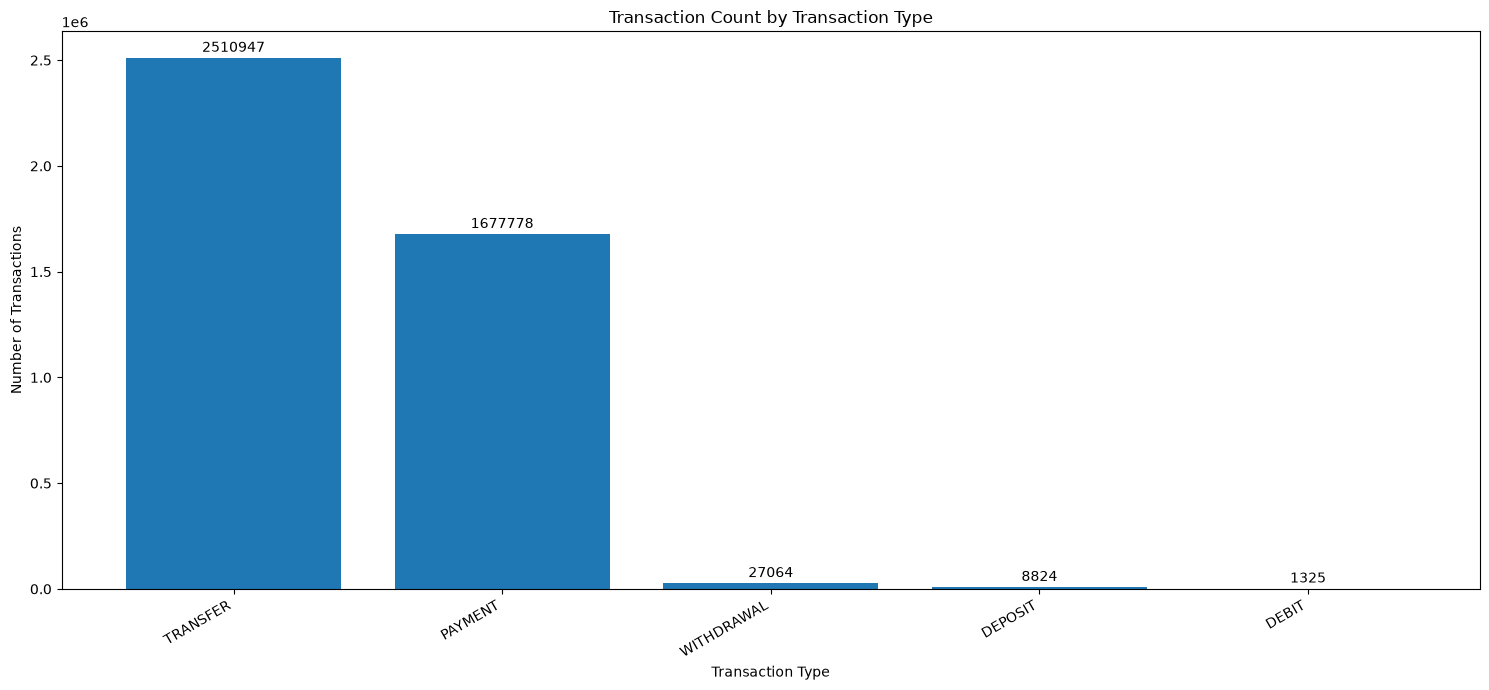

In [122]:
# Sort by transaction count
summary = summary.sort_values("count", ascending=False)

# Display monetary values to 2 decimal places and fraud rate as a percentage
summary["total_amount"] = summary["total_amount"].round(2)
summary["median_amount"] = summary["median_amount"].round(2)
summary["fraud_rate"] = (summary["fraud_rate"] * 100).round(2)

print("===== TRANSACTION-TYPE SUMMARY =====")
print(summary.to_string())

# 3. Plot transaction counts by type. X - Axis
counts = df["transactionType"].value_counts().sort_values(
    ascending=False
)

print("Debug MODE!!!")
print(counts.index)
print(counts.values)
print("Debug MODE!!!")

plt.figure(figsize=(15, 7))
bars = plt.bar(counts.index, counts.values)

plt.title("Transaction Count by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30, ha="right")

# Label each bar with its count
plt.bar_label(bars, fmt="%.0f", padding=2)

plt.tight_layout()
plt.show()

### Transaction Amount Distribution

Display the amount distribution and discuss its skewness.

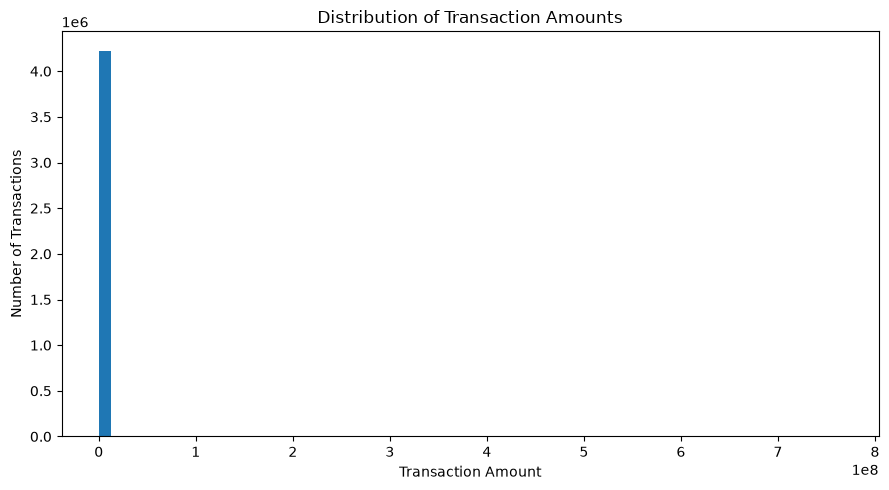

In [82]:
# 4. Plot the distribution of transaction amounts
plt.figure(figsize=(9, 5))

plt.hist(df["amount"].dropna(), bins=60)
# plt.xlim(0, 400000)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

#### Distribution and Skew of Transaction Amounts

The histogram shows that the transaction amount distribution is **right-skewed**. Most transactions involve relatively small amounts, while a smaller number involve very large amounts, creating a long tail to the right. This means that a few unusually large transactions may significantly affect the mean transaction amount. Therefore, the median is useful for describing a typical transaction because it is less affected by extreme values.

### Class Imbalance and Monetary Value

Discuss the distribution of fraudulent versus non-fraudulent transactions. Distinguish transaction counts from total monetary value.

Fraud label balance : 2,233,118 rows have isFraud = 1 and 1,992,840 have isFraud = 0. The overall labeled fraud rate is 52.84%. This is a slight majority of fraud labels, not the low fraud prevalence usually expected in many real financial systems.

This indicates **class imbalance**, as fraudulent transactions substantially outnumber legitimate transactions. 

#### Transaction Counts Versus Total Monetary Value

Transaction counts and total monetary value measure different aspects of transaction activity. Transaction counts show how frequently each transaction type occurs, while total monetary value represents the sum of the amounts involved in those transactions.

A transaction type may have a high count but a relatively low total monetary value if its individual transactions are generally small. Conversely, a less frequent transaction type may account for a higher total monetary value if its transactions involve larger amounts.

## Question 2: Represent Transactions as Matrices and Vectors

### 2(a) Random Sampling of the Cleaned Dataset

Take a random sample of up to 2,000 transactions from the cleaned dataset. State the sample size and random seed, if used.

In [83]:
random_2k_sample = cleaned_df.sample(n=2000, random_state=42)

cols = ["amount", "oldBalInitiator", "newBalInitiator",
"oldBalRecipient", "newBalRecipient"]

X = random_2k_sample[cols].to_numpy(dtype=float)
n = X.shape[0]  # rows
print(pd.DataFrame(X[:3], columns=cols))
print(X.shape, X.T.shape, (X.T @ X).shape, (X @ X.T).shape)

     amount  oldBalInitiator  newBalInitiator  oldBalRecipient  \
0  20770.75         20770.75             0.00       4512001.36   
1  12906.71         12906.71             0.00       6579534.39   
2    784.66          5040.78          4256.12         28491.57   

   newBalRecipient  
0       4532772.11  
1       6592441.11  
2         29276.24  
(2000, 5) (5, 2000) (5, 5) (2000, 2000)



### Stating Matrix Dimensions

Let $X$ be a matrix containing 2,000 transactions, each represented by 5 numerical features.

#### 1. Matrix $X$

The matrix $X$ has dimensions $2000 \times 5$.

- **2,000 rows:** Each row represents one transaction.
- **5 columns:** Each column represents one numerical feature.

Therefore, $X \in \mathbb{R}^{2000 \times 5}$.

#### 2. Transpose of $X$: $X^T$

Transposing a matrix swaps its rows and columns.

Therefore, $X^T$ has dimensions $5 \times 2000$.

- **5 rows:** Each row corresponds to one of the original features.
- **2,000 columns:** Each column corresponds to one transaction.

Therefore, $X^T \in \mathbb{R}^{5 \times 2000}$.

#### 3. Product $X^T X$

The dimensions are:

$$
(5 \times 2000)(2000 \times 5) = 5 \times 5
$$

The two inner dimensions, both equal to 2,000, match and are eliminated during multiplication. The remaining outer dimensions determine the result.

The result is a $5 \times 5$ matrix. It represents relationships between the five features across all 2,000 transactions.

#### 4. Product $XX^T$

The dimensions are:

$$
(2000 \times 5)(5 \times 2000) = 2000 \times 2000
$$

The two inner dimensions, both equal to 5, match and are eliminated during multiplication. The remaining outer dimensions determine the result.

The result is a $2000 \times 2000$ matrix. It represents pairwise relationships between the 2,000 transactions, with each entry comparing two transactions across their five features.


**Account IDs and transaction types are excluded from this numeric representation because they have no effect on the analysis of the dataset.**

### 2(b) Computing the mean vector $\mu$

In [84]:
J = np.ones(n)
mu = X.T @ J / n

print("Our mean vector", mu)

Our mean vector [   22735.737445   21283724.57991501 21263621.66259001  1792654.28074
  1811649.09262   ]


#### Verifying it against pandas' mean

In [85]:
pandas_mean = random_2k_sample[cols].mean().to_numpy()

print("Pandas' mean", pandas_mean)
print("Match?", np.allclose(mu, pandas_mean))

Pandas' mean [   22735.737445 21283724.579915 21263621.66259   1792654.28074
  1811649.09262 ]
Match? True


#### The total amount expressed as a dot product with 1

In [86]:
print(X[:, 0] @ J) 

45471474.889999986


#### Sanity check with pandas' sum

In [87]:
print(random_2k_sample["amount"].sum())

45471474.89


#### Why a column of $X$ belongs to $\mathbb{R}^n$, whereas $x_i$ belongs to $\mathbb{R}^5$

A column of $X$ belongs to $\mathbb{R}^n$ because it contains $n$ real-valued entries, one for each observation in the dataset. In contrast, $x_i$ belongs to $\mathbb{R}^5$ because it represents a single observation described by five features: the transaction amount, the initiator's old and new balances, and the recipient's old and new balances.

Therefore, $X \in \mathbb{R}^{n \times 5}$, where $n$ represents the number of observations and $5$ represents the number of features.

### 2(c) Vector Similarity, Distance, and Fraud Interpretation

In [88]:
# Standardize X
mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1  # Avoid division by zero for constant features
Z = (X - mean) / std

# Choose two nonzero standardized transaction vectors
nonzero_indices = np.flatnonzero(np.linalg.norm(Z, axis=1) > 0)

i, j = nonzero_indices[:2]
u, v = Z[i], Z[j]

# Calculate vector properties
norm_u = np.linalg.norm(u)
norm_v = np.linalg.norm(v)
distance_standardized = np.linalg.norm(u - v)
dot_product = u @ v

cosine_similarity = dot_product / (norm_u * norm_v)
cosine_similarity = np.clip(cosine_similarity, -1, 1)

angle_degrees = np.degrees(np.arccos(cosine_similarity))

# Compare raw and standardized distances
distance_raw = np.linalg.norm(X[i] - X[j])

print("Transaction indices:", i, j)
print("||u||₂:", norm_u)
print("||v||₂:", norm_v)
print("||u - v||₂ (standardized):", distance_standardized)
print("uᵀv:", dot_product)
print("Cosine similarity:", cosine_similarity)
print("Angle (degrees):", angle_degrees)
print("Raw distance:", distance_raw)
print("Standardized distance:", distance_standardized)

Transaction indices: 0 1
||u||₂: 0.7143845954617484
||v||₂: 1.0423774253742117
||u - v||₂ (standardized): 0.40667644783992224
uᵀv: 0.7157551569675595
Cosine similarity: 0.9611859352773849
Angle (degrees): 16.015740565221535
Raw distance: 2918399.031310184
Standardized distance: 0.40667644783992224


### Why similarity alone does not determine fraud
Similarity alone does not determine fraud because it only measures how similar two transactions are in terms of their feature vectors, not whether they are fraudulent. Two transactions may have similar amounts and account balances but different fraud labels. Likewise, a fraudulent transaction may be very different from other fraudulent transactions. Therefore, fraud detection requires considering other factors, such as transaction type, account behavior, and historical patterns, alongside similarity measures.

## Question 3: Operations Monitoring and Transfer Investigation

### 3(a) Transaction Volume by Step and Type

#### Constructing the Step-by-Type Count Matrix

Build the matrix $M \in \mathbb{R}^{S \times 5}$ using the full cleaned dataset, with steps as rows and transaction types as columns.

In [89]:
# A step-by-type count matrix M from the full cleaned data
M = (
    cleaned_df.groupby(["step", "transactionType"])
      .size()
      .unstack(fill_value=0)
      .sort_index()
)

# Label the rows and columns
M.index.name = "Step"
M.columns.name = "Transaction Type"

print("Matrix shape:", M.shape)
print(M.head())

Matrix shape: (193, 5)
Transaction Type  DEBIT  DEPOSIT  PAYMENT  TRANSFER  WITHDRAWAL
Step                                                           
0                     0        0     8588     11416           0
1                     0       57     8589     11164           0
2                     0        7     8546     11037           0
3                     1       14     8525     11112           2
4                     0        0     8580     11047           0


#### Calculating Total Transaction Counts per Step

Use $M\mathbf{1}_5$ to calculate the total number of transactions at each step.

In [90]:
# Create a vector of five ones
one_vector = np.ones(5)

# Calculate total transactions at each step
step_counts = M.to_numpy() @ one_vector

# Keep the step labels attached to the results
step_counts = pd.Series(
    step_counts,
    index=M.index,
    name="Total Transactions"
)

print(step_counts.head(193))

Step
0      20004.0
1      19810.0
2      19590.0
3      19654.0
4      19627.0
        ...   
188    24751.0
189    24457.0
190    24347.0
191    23898.0
192    23422.0
Name: Total Transactions, Length: 193, dtype: float64


In [91]:
print("Results agree:", np.allclose(step_counts, M.sum(axis=1)))

Results agree: True


#### Plotting Transaction Counts Against Step

Visualise transaction volume across steps and identify the three busiest steps and their dominant transaction types.

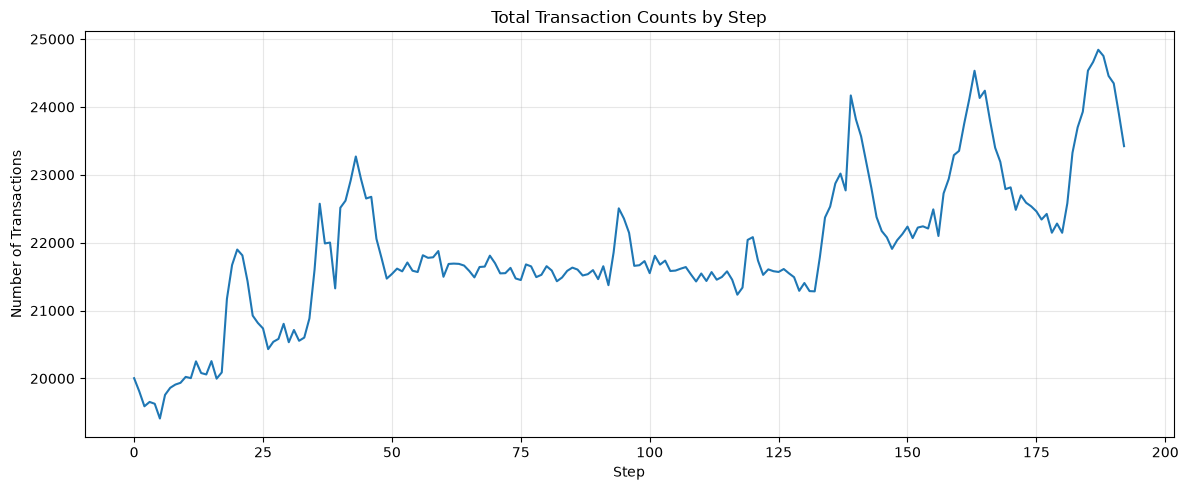

In [92]:
plt.figure(figsize=(12, 5))

plt.plot(step_counts.index, step_counts.values)

plt.title("Total Transaction Counts by Step")
plt.xlabel("Step")
plt.ylabel("Number of Transactions")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Identify the three busiest steps

In [93]:
top_three = step_counts.nlargest(3)

print("Three busiest steps:")
print(top_three)

Three busiest steps:
Step
187    24842.0
188    24751.0
186    24662.0
Name: Total Transactions, dtype: float64


In [94]:
busiest_steps = top_three.rename_axis("Step").reset_index()
print(busiest_steps)

   Step  Total Transactions
0   187             24842.0
1   188             24751.0
2   186             24662.0


#### The dominant transaction type at each busy step

In [95]:
dominant_types = M.loc[top_three.index].idxmax(axis=1)

results = pd.DataFrame({
    "Total Transactions": top_three,
    "Dominant Transaction Type": dominant_types,
    "Dominant Type Count": M.loc[top_three.index].max(axis=1)
})

print(results)

      Total Transactions Dominant Transaction Type  Dominant Type Count
Step                                                                   
187              24842.0                  TRANSFER                14530
188              24751.0                  TRANSFER                14585
186              24662.0                  TRANSFER                14569


### 3(b) Transfer Balance-Change Investigation

#### Selecting Sampled Transfer Transactions

Extract the TRANSFER records from the sampled transaction matrix $X$.

In [96]:
transfer_sample = random_2k_sample[
    random_2k_sample["transactionType"] == "TRANSFER"
].copy()

print("Sampled TRANSFER records:", len(transfer_sample))
print(transfer_sample["isFraud"].value_counts().sort_index())

Sampled TRANSFER records: 1208
isFraud
0     130
1    1078
Name: count, dtype: int64


#### Calculating Balance Changes Using Matrix Multiplication

Calculate the balance changes using $Y = X_T B^T$.

#### Constructing $X_T$.

In [97]:
cols = [
    "amount",
    "oldBalInitiator",
    "newBalInitiator",
    "oldBalRecipient",
    "newBalRecipient"
]

X_T = transfer_sample[cols].to_numpy()

print("X_T shape:", X_T.shape)

X_T shape: (1208, 5)


#### Calculating the balance changes using matrix multiplication

In [98]:
B = np.array([
    [0, -1,  1,  0,  0],
    [0,  0,  0, -1,  1]
])

Y = X_T @ B.T

print("B shape:", B.shape)
print("B.T shape:", B.T.shape)
print("Y shape:", Y.shape)

print("First five balance changes:")
print(Y[:5])

B shape: (2, 5)
B.T shape: (5, 2)
Y shape: (1208, 2)
First five balance changes:
[[-20770.75  20770.75]
 [-12906.71  12906.72]
 [-17847.4   17847.4 ]
 [  -434.98    434.98]
 [-11350.83  11350.83]]


#### Verifying Balance Changes by Direct Subtraction

Compare the matrix-computed balance changes against the balance changes obtained directly from the original balance values.

In [99]:
delta_bI_direct = (
    transfer_sample["newBalInitiator"].to_numpy()
    - transfer_sample["oldBalInitiator"].to_numpy()
)

delta_bR_direct = (
    transfer_sample["newBalRecipient"].to_numpy()
    - transfer_sample["oldBalRecipient"].to_numpy()
)

print("Initiator matches:",
      np.allclose(Y[:, 0], delta_bI_direct))

print("Recipient matches:",
      np.allclose(Y[:, 1], delta_bR_direct))

Initiator matches: True
Recipient matches: True


#### Investigating Residuals and Mismatches

Calculate the initiator and recipient residuals:

$$
r_I = \Delta b_I + a
$$

$$
r_R = \Delta b_R - a
$$

Use a declared tolerance of 0.01 monetary units to identify mismatches. Compare mismatch proportions between fraudulent and legitimate transactions, reporting the group counts.

In [100]:
# Transaction amounts from sampled TRANSFER records
a = transfer_sample["amount"].to_numpy()
# print("Sum entire amount column?", a)

# Balance-change residuals
rI = Y[:, 0] + a
rR = Y[:, 1] - a

print(rI, rR)

# Declare the monetary tolerance
tolerance = 0.01

print("Tolerance:", tolerance)
print("First 10 initiator residuals:", rI[:10])
print("First 10 recipient residuals:", rR[:10])

[ 0.00000000e+00  0.00000000e+00 -2.18278728e-11 ...  0.00000000e+00
  1.19325705e-09  0.00000000e+00] [ 0.00000000e+00  1.00000007e-02  0.00000000e+00 ...  1.00000001e-02
  0.00000000e+00 -4.36557457e-11]
Tolerance: 0.01
First 10 initiator residuals: [ 0.00000000e+00  0.00000000e+00 -2.18278728e-11  0.00000000e+00
  0.00000000e+00  1.68489500e+04  0.00000000e+00  0.00000000e+00
  1.49157131e-09  0.00000000e+00]
First 10 recipient residuals: [ 0.00000000e+00  1.00000007e-02  0.00000000e+00  1.04591891e-11
  7.45785655e-11 -1.68489500e+04  9.99999996e-03  8.38156211e-11
  0.00000000e+00 -1.76953563e-10]


#### Identifying residuals outside the tolerance

In [126]:
# Check each residual independently
initiator_mismatch = np.abs(rI) > tolerance + 1e-9
recipient_mismatch = np.abs(rR) > tolerance + 1e-9

print("Returning True or False?", initiator_mismatch)

# Overall mismatch: either balance fails the check
mismatch = initiator_mismatch | recipient_mismatch

print("Transfer records:", len(transfer_sample))
print("Initiator mismatches:", initiator_mismatch.sum())
print("Recipient mismatches:", recipient_mismatch.sum())
print("Overall mismatches:", mismatch.sum())
print("Overall mismatch proportion:", mismatch.mean())

Returning True or False? [False False False ... False False False]
Transfer records: 1208
Initiator mismatches: 177
Recipient mismatches: 167
Overall mismatches: 177
Overall mismatch proportion: 0.14652317880794702


#### Comparing mismatch proportions

In [120]:
# Attach mismatch results to the sampled TRANSFER records
transfer_sample["mismatch"] = mismatch

# Group by fraud label and calculate counts and proportions
comparison = transfer_sample.groupby("isFraud").agg(
    group_count=("mismatch", "size"),
    mismatch_count=("mismatch", "sum"),
    mismatch_proportion=("mismatch", "mean")
)

# Add percentages for easier interpretation
comparison["mismatch_percentage"] = (
    comparison["mismatch_proportion"] * 100
)

comparison.index = comparison.index.map({
    0: "Legitimate (0)",
    1: "Fraud (1)"
})

print(comparison)

                group_count  mismatch_count  mismatch_proportion  \
isFraud                                                            
Legitimate (0)          130              11             0.084615   
Fraud (1)              1078             166             0.153989   

                mismatch_percentage  
isFraud                              
Legitimate (0)             8.461538  
Fraud (1)                 15.398887  


The mismatch proportion for the fraudulent labels is ``0.153989`` which is greater than that of the legitimate labels ``0.084615``. And their reported group counts are  **130** for legitimate and **1078** for fraudulent.

### 3(c) Fraud Counts and Rates by Step

#### Calculating Fraud Counts and Rates

Calculate the fraud count and fraud rate for each step using the full cleaned dataset.

In [125]:
step_fraud = cleaned_df.groupby("step").agg(
    total_transactions=("isFraud", "size"),
    fraud_count=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

step_fraud["fraud_percentage"] = step_fraud["fraud_rate"] * 100

print(step_fraud.head(15))

      total_transactions  fraud_count  fraud_rate  fraud_percentage
step                                                               
0                  20004        11192    0.559488         55.948810
1                  19810        10957    0.553104         55.310449
2                  19590        10873    0.555028         55.502808
3                  19654        10951    0.557189         55.718938
4                  19627        10893    0.555001         55.500076
5                  19410        10829    0.557908         55.790829
6                  19758        11060    0.559773         55.977326
7                  19862        11083    0.558000         55.800020
8                  19910        11012    0.553089         55.308890
9                  19936        11014    0.552468         55.246790
10                 20023        11223    0.560505         56.050542
11                 20005        11152    0.557461         55.746063
12                 20252        11326    0.55925

In [113]:
# Find the step with the highest fraud rate
highest_fraud_step = step_fraud["fraud_rate"].idxmax()
highest_fraud_rate = step_fraud.loc[highest_fraud_step, "fraud_percentage"]

print("Step with the highest fraud rate:", highest_fraud_step)
print(f"Highest fraud rate: {highest_fraud_rate:.2f}%")

# Display all statistics for that step
print("\nDetails:")
print(step_fraud.loc[highest_fraud_step])

Step with the highest fraud rate: 10
Highest fraud rate: 56.05%

Details:
total_transactions    20023.000000
fraud_count           11223.000000
fraud_rate                0.560505
fraud_percentage         56.050542
Name: 10, dtype: float64


#### Steps with the most fraud cases

In [118]:
print(step_fraud.sort_values(
    by="fraud_count", ascending=False
).head(10))

      total_transactions  fraud_count  fraud_rate  fraud_percentage
step                                                               
165                24239        11969    0.493791         49.379100
185                24535        11967    0.487752         48.775219
168                23191        11930    0.514424         51.442370
166                23803        11923    0.500903         50.090325
57                 21777        11854    0.544336         54.433577
169                22789        11846    0.519812         51.981219
190                24347        11846    0.486549         48.654865
69                 21809        11840    0.542895         54.289514
59                 21877        11830    0.540751         54.075056
184                23929        11830    0.494379         49.437921


#### Plotting Fraud Rates Against Step

Visualise fraud rates by step and include transaction counts for context.

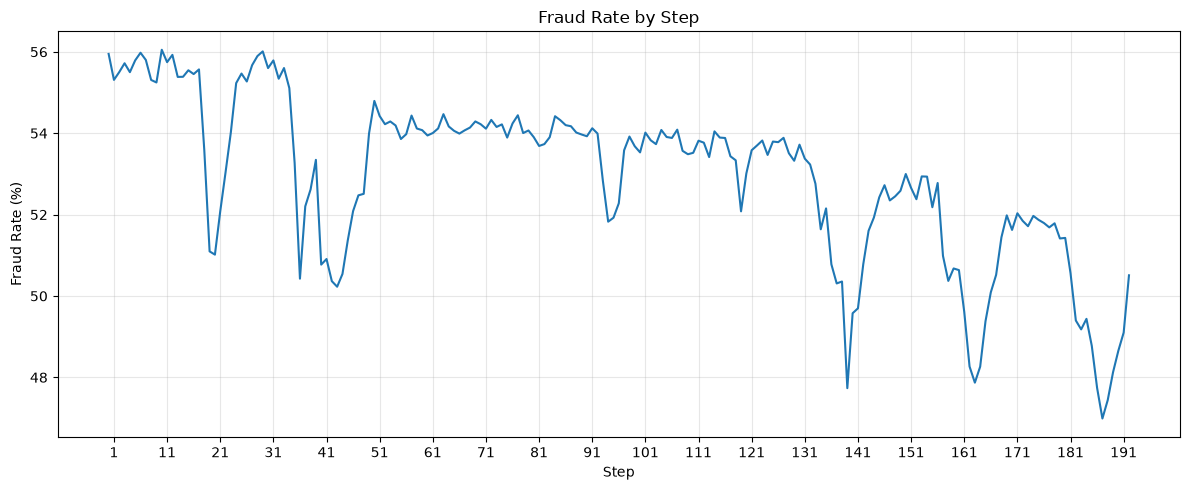

In [104]:
# plt.figure(figsize=(9, 5))

# plt.scatter(
#     step_fraud["total_transactions"],
#     step_fraud["fraud_rate"] * 100
# )

# plt.title("Transaction Counts vs Fraud Rates by Step")
# plt.xlabel("Step Transaction Count")
# plt.ylabel("Fraud Rate (%)")

# plt.tight_layout()
# plt.show()
plt.figure(figsize=(12, 5))

plt.plot(
    step_fraud.index,
    step_fraud["fraud_rate"] * 100
)

plt.title("Fraud Rate by Step")
plt.xlabel("Step")
plt.ylabel("Fraud Rate (%)")

plt.xticks(range(1, 194, 10))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

For the busy step (188), it is seen that it has a low fraud rate compared to a step (10) with a high fraud rate that is evidenced with a low transaction count

#### Comparing Transaction Volume and Fraud Risk

Compare a busy step with a high-fraud-rate step and explain why high transaction volume and high fraud risk require different operational responses.

Since step 188 has the highest transaction volume but a relatively low fraud rate, the provider should consider increasing customer support capacity during this period to manage demand and maintain service quality, while continuing routine fraud monitoring.

In contrast, step 10 has the highest fraud rate despite having one of the lowest transaction counts. This warrants further investigation to determine whether the high rate reflects a genuine suspicious pattern or is influenced by the small number of transactions. The provider should examine the fraudulent transactions and apply targeted monitoring where necessary.

Therefore, high transaction volume and high fraud rate require different responses: volume informs operational capacity planning, while fraud rates help identify periods for further investigation. Both fraud counts and transaction counts should be considered to avoid drawing misleading conclusions from percentages alone.

### 3(d) Management Recommendations

#### Recommendation 1: Operational Capacity Planning

Monitor fraud rate and transaction volume together by step, and investigate high-rate periods rather than staffing only according to transaction volume.

#### Recommendation 2: Fraud Monitoring and Investigation

Propose an action based on the fraud-rate and transfer-investigation findings.
Prioritize review rules that combine transfer balance residuals with transaction amount and other context, while checking false positives

## Question 4: Predict Next-Step Transaction Volume

### 4(a) Time-Series Preparation and Train-Test Split

#### Checking Step Continuity and Investigating Gaps

Check whether simulation steps are consecutive. Investigate any missing steps before deciding whether they represent zero-transaction periods.

In [105]:
# Count transactions at each step using the full cleaned data
ct = cleaned_df.groupby("step").size()
print(ct)
# Check the observed steps
steps = ct.index.to_numpy()
print(steps)
step_diffs = np.diff(steps)
print(step_diffs.size)
gaps = step_diffs[step_diffs > 1]
print(gaps)

step
0      20004
1      19810
2      19590
3      19654
4      19627
       ...  
188    24751
189    24457
190    24347
191    23898
192    23422
Length: 193, dtype: int64
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192]
192
[]


Upon investigation, there are no gaps to treat as zero-count periods.

#### Sorting Steps and Creating Adjacent Input-Target Pairs

Sort the steps chronologically and construct adjacent pairs $(c_t, c_{t+1})$, where $c_t$ is the transaction count at step $t$.

In [106]:
# Sort steps chronologically
ct = cleaned_df.groupby("step").size().sort_index()

# Align each step's count with the following observed step
pairs = pd.DataFrame({
        "step_t": ct.index,
        "c_t": ct.to_numpy(),
        "step_next": ct.index.to_numpy()[1:].tolist() + [np.nan],
        "c_next": ct.shift(-1).to_numpy()
    })

# Keep only pairs whose steps differ by exactly one hour
pairs = pairs[
    (pairs["step_next"] - pairs["step_t"] == 1)
].copy()

print("Number of valid adjacent pairs:", len(pairs))
print(pairs.head(193))

Number of valid adjacent pairs: 192
     step_t    c_t  step_next   c_next
0         0  20004        1.0  19810.0
1         1  19810        2.0  19590.0
2         2  19590        3.0  19654.0
3         3  19654        4.0  19627.0
4         4  19627        5.0  19410.0
..      ...    ...        ...      ...
187     187  24842      188.0  24751.0
188     188  24751      189.0  24457.0
189     189  24457      190.0  24347.0
190     190  24347      191.0  23898.0
191     191  23898      192.0  23422.0

[192 rows x 4 columns]


#### Constructing the Design Matrix and Target Vector

Construct the design matrix using rows $(1, c_t)$ and the corresponding target vector $y = c_{t+1}$.

In [107]:
# Design matrix and target vector
X = np.column_stack([
    np.ones(len(pairs)),
    pairs["c_t"].to_numpy()
])

y = pairs["c_next"].to_numpy()

print("Design matrix X:", X.shape)
print("Target vector y:", y.shape)

Design matrix X: (192, 2)
Target vector y: (192,)


#### Chronological Training and Testing Split

Use the earliest 70% of pairs for training and the remaining 30% for testing.

In [108]:
n_pairs = len(pairs)
n_train = int(0.70 * n_pairs)

# Chronological split: no shuffling
X_train = X[:n_train]
y_train = y[:n_train]

X_test = X[n_train:]
y_test = y[n_train:]

train_pairs = pairs.iloc[:n_train]
test_pairs = pairs.iloc[n_train:]

print("Total pairs:", n_pairs)
print("Training pairs:", len(train_pairs))
print("Testing pairs:", len(test_pairs))

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print()
print(
    "Split boundary:",
    f"last training pair: {train_pairs.iloc[-1]['step_t']} -> "
    f"{train_pairs.iloc[-1]['step_next']};",
    f"first testing pair: {test_pairs.iloc[0]['step_t']} -> "
    f"{test_pairs.iloc[0]['step_next']}"
)

Total pairs: 192
Training pairs: 134
Testing pairs: 58
X_train: (134, 2)
y_train: (134,)
X_test: (58, 2)
y_test: (58,)

Split boundary: last training pair: 133.0 -> 134.0; first testing pair: 134.0 -> 135.0


- **Split boundary:**
  - Last training pair: $133.0 \rightarrow 134.0$
  - First testing pair: $134.0 \rightarrow 135.0$

- **Matrix dimensions:**

  | Variable | Dimensions |
  |---|---|
  | $X_{\text{train}}$ | $(134, 2)$ |
  | $y_{\text{train}}$ | $(134,)$ |
  | $X_{\text{test}}$ | $(58, 2)$ |
  | $y_{\text{test}}$ | $(58,)$ |

- **Why not randomly split the data?**

  A random split is inappropriate because it can mix earlier and later periods between the training and testing sets. This can make the evaluation less representative of real-world forecasting, where the model is trained on past observations and used to predict future transaction counts.

### 4(b) Least-Squares Model Fitting and Evaluation
#### Fitting the Linear Forecasting Model

Fit the coefficients $\beta_0$ and $\beta_1$ using least squares:

$$
A_{\text{train}}\beta \approx y_{\text{train}}
$$

In [109]:
# Fit beta using the training data
beta, residuals, rank, singular_values = np.linalg.lstsq(
            X_train, y_train, rcond=None
        )

beta0, beta1 = beta

print("Intercept (beta0):", beta0)
print("Slope (beta1):", beta1)

# Predict transaction counts for the test pairs
y_pred = X_test @ beta

# Persistence baseline: predict next hour = current hour
y_persistence = X_test[:, 1]

# Evaluation metrics
mae_model = np.mean(np.abs(y_test - y_pred))
rmse_model = np.sqrt(np.mean((y_test - y_pred) ** 2))

mae_persistence = np.mean(np.abs(y_test - y_persistence))
rmse_persistence = np.sqrt(
    np.mean((y_test - y_persistence) ** 2)
)

print("\nLinear model:")
print("MAE:", mae_model)
print("RMSE:", rmse_model)

print("\nPersistence baseline:")
print("MAE:", mae_persistence)
print("RMSE:", rmse_persistence)

Intercept (beta0): 1732.891072042734
Slope (beta1): 0.9197744852826278

Linear model:
MAE: 274.5735050687168
RMSE: 369.3134564161847

Persistence baseline:
MAE: 275.8103448275862
RMSE: 352.3948852812904



#### Least-Squares Model Fitting and Evaluation

The linear forecasting model was fitted using the training data and the least-squares method, implemented with `np.linalg.lstsq()`. The objective was to find the coefficients that minimise the sum of squared differences between the observed next-step transaction counts and the model's predictions.

The model is defined as:

$$
\hat{c}_{t+1} = \beta_0 + \beta_1 c_t
$$

The estimated coefficients were:

- **Intercept ($\beta_0$):** 1732.8911
- **Slope ($\beta_1$):** 0.9198

The fitted forecasting equation is therefore:

$$
\boxed{\hat{c}_{t+1} = 1732.8911 + 0.9198c_t}
$$

The intercept represents the model's predicted next-step transaction count when the current count is zero. The slope indicates that, on average, an increase of one transaction in the current step corresponds to an increase of approximately 0.9198 transactions in the predicted next step. The positive slope suggests a positive relationship between consecutive transaction counts. Since the slope is slightly below 1, the model also exhibits mild mean reversion: changes in the current count are reflected somewhat less strongly in the predicted next-step count.

The model predictions were obtained by multiplying the test design matrix by the fitted coefficient vector:

$$
\hat{y}_{\text{test}} = A_{\text{test}}\beta
$$

Each prediction is a linear combination of the two columns of the test design matrix: a column of ones and a column containing the current transaction counts. Consequently, the prediction vector belongs to the column space, or span of the columns, of $A_{\text{test}}$.

#### Evaluating Forecast Accuracy on the Held-Out Test Set

The model was evaluated on the held-out test set using two error metrics: mean absolute error (MAE) and root mean squared error (RMSE). Both metrics compare the observed next-step counts with the predicted counts.

**Mean Absolute Error (MAE)** measures the average magnitude of the absolute prediction errors:

$$
\mathrm{MAE}=\frac{1}{m}\sum_{i=1}^{m}|y_i-\hat{y}_i|
$$

where $m$ is the number of test pairs, $y_i$ is the observed next-step transaction count, and $\hat{y}_i$ is the predicted count.

**Root Mean Squared Error (RMSE)** measures the square root of the average squared prediction errors:

$$
\mathrm{RMSE}=\sqrt{\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2}
$$

Unlike MAE, RMSE penalises larger errors more heavily because the errors are squared before averaging. Both metrics are expressed in transaction-count units, and lower values indicate better predictive accuracy.

#### Comparison with the Persistence Baseline

The linear model was compared against the persistence baseline, which assumes that the next step's transaction count will be identical to the current step's count:

$$
\hat{c}_{t+1}=c_t
$$

The baseline predictions were taken directly from the current-count column of $X_{\text{test}}$. Both models were evaluated against the same observed test targets, ensuring a fair comparison.

The results were:

| Model | MAE | RMSE |
|---|---:|---:|
| Linear forecasting model | 274.57 | 369.31 |
| Persistence baseline | 275.81 | 352.39 |
| Difference (linear − baseline) | -1.24 | +16.92 |

The linear model achieved an MAE of 274.57, compared with 275.81 for the persistence baseline. Its MAE was therefore lower by approximately 1.24 transactions, an improvement of about 0.45%.

However, the linear model's RMSE was 369.31, compared with 352.39 for the persistence baseline. The linear model's RMSE was higher by approximately 16.92 transactions, or 4.80%. This indicates that the linear model performed worse when larger prediction errors were given greater weight.

The fact that RMSE exceeds MAE for both models suggests that some prediction errors are larger than others. The higher RMSE of the linear model relative to the baseline indicates that its squared errors were greater overall, despite its slightly lower average absolute error.

#### Interpretation and Conclusion

The linear forecasting model provides only a marginal improvement over the persistence baseline in terms of MAE, but it performs worse in terms of RMSE. Therefore, it cannot be considered consistently superior across both evaluation metrics.

For operational planning, the persistence baseline remains a strong reference because it is simple and requires no fitted coefficients. The linear model may be useful when reducing average absolute error is the priority, but its higher RMSE suggests caution where unusually large forecasting errors could disrupt staffing or processing capacity.

Overall, the results demonstrate the importance of evaluating forecasts using multiple metrics and comparing them with a simple baseline. Further improvements could involve testing additional forecasting methods and incorporating features such as the hour of the day and transaction counts from 24 hours earlier to capture daily patterns. Any improved model should be evaluated using the same chronological train-test split to ensure a fair comparison.


### 4(c) Visualisation and Interpretation of Forecasts
#### Plotting Observed and Predicted Transaction Counts

Plot the observed test counts, linear model predictions, and persistence baseline against the target simulation step.

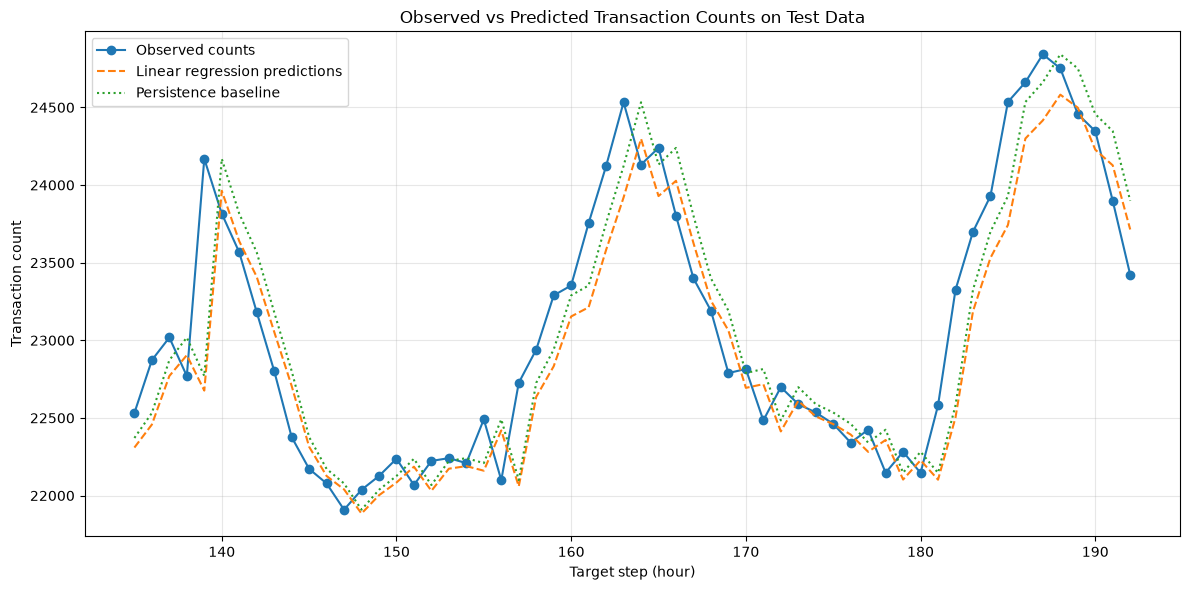

In [110]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_pairs["step_next"],
    y_test,
    label="Observed counts",
    marker="o"
)

plt.plot(
    test_pairs["step_next"],
    y_pred,
    label="Linear regression predictions",
    linestyle="--"
)

plt.plot(
    test_pairs["step_next"],
    y_persistence,
    label="Persistence baseline",
    linestyle=":"
)

plt.xlabel("Target step (hour)")
plt.ylabel("Transaction count")
plt.title("Observed vs Predicted Transaction Counts on Test Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Does the Model Improve on the Baseline?

The linear model provides only a marginal improvement over the persistence baseline in terms of MAE. Its MAE is approximately 274.57, compared with 275.81 for the baseline, representing an improvement of about 0.45%.

The model's slope of approximately 0.9198, which is slightly below 1, suggests mild mean reversion: changes in the current transaction count are reflected somewhat less strongly in the predicted next-step count, while the positive intercept shifts predictions upward.

However, the linear model has a higher RMSE than the persistence baseline (369.31 versus 352.39), representing an increase of approximately 4.80%. This indicates worse performance when larger prediction errors are penalised more heavily.

Overall, the linear model does not consistently outperform the persistence baseline. 


#### How Forecasting Errors Affect Staffing

- **Underprediction:** When the actual transaction count exceeds the forecast, there may be insufficient staff to handle demand. This can lead to longer queues, slower transaction processing, increased workloads, and reduced customer satisfaction.

- **Overprediction:** When the forecast exceeds the actual transaction count, more staff than necessary may be scheduled. This can increase operating costs and result in underutilised employees.

- **Large prediction errors:** The linear model's higher RMSE (369.31) compared with the persistence baseline (352.39) indicates that it performs worse when larger errors are penalised more heavily. Such errors may cause significant staffing mismatches during unusually busy or quiet hours, making resource allocation less efficient.

Overall, the provider should consider both the size of forecasting errors and the consequences of underprediction and overprediction when planning staffing levels and transaction-processing capacity. Since the persistence baseline has a lower RMSE, it may be the more reliable option when avoiding large forecasting errors is a priority.

#### Discussion of Findings

Both forecasting methods capture the general level of transaction volume but may lag behind at turning points, such as sudden increases or decreases in activity. This limitation arises because both methods rely only on the previous hour's transaction count and do not account for other factors that may influence transaction volume.

The linear model provides only a marginal improvement over the persistence baseline in terms of MAE, with values of 274.57 and 275.81, respectively. However, its higher RMSE of 369.31, compared with 352.39 for the baseline, indicates that it performs worse when larger prediction errors are penalised more heavily. Therefore, the linear model does not consistently outperform the baseline, and the simpler persistence method remains a strong option for forecasting next-step transaction volume.